# Intial Data Sets

In [2]:
# Space to keep intial data sets
from io import StringIO
from pathlib import Path
from urllib.request import urlopen

import pandas as pd


# Clean up Data

In [ ]:

roster = pd.read_csv(
    "Audience SIze by Career Age - Sheet1.csv",
    usecols=["Artist", "Plant?", "First release date"],
).rename(columns={
    "Artist": "artist",
    "Plant?": "plant",
    "First release date": "first_release",
})

snapshot = pd.Timestamp("2026-10-07")
release = roster["first_release"]
earliest = pd.to_datetime(release, format="mixed")
latest = earliest.copy()

# Uses the range of possible dates when only a month or year is known.
month_only = release.str.len().eq(7)
year_only = release.str.len().eq(4)
latest.loc[month_only] = earliest.loc[month_only] + pd.offsets.MonthEnd(0)
latest.loc[year_only] = earliest.loc[year_only] + pd.offsets.YearEnd(0)

def months_since(dates):
    return (
        (snapshot.year - dates.dt.year) * 12
        + snapshot.month - dates.dt.month
        - (snapshot.day < dates.dt.day).astype(int)
    )

roster["months_since_release"] = (
    months_since(earliest) + months_since(latest)
) / 2

url = (
    "https://web.archive.org/web/20261007195344id_/"
    "https://kworb.net/spotify/listeners.html"
)
with urlopen(url, timeout=30) as response:
    html = response.read().decode("utf-8")

ranking = pd.read_html(StringIO(html), match="PkListeners")[0].rename(
    columns={"Artist": "artist", "Listeners": "monthly_listeners"}
)

for table in (roster, ranking):
    table["key"] = table["artist"].str.strip().str.casefold()

df = roster.merge(
    ranking[["key", "monthly_listeners"]],
    on="key",
    how="left",
    validate="one_to_one",
).drop(columns="key")

display(df)

,artist,plant,first_release,months_since_release,monthly_listeners
0,Taylor Swift,Yes,2006-06-19,243.0,105964047.0
1,JENNIE,Yes,2018-11-12,94.0,47979524.0
2,Malcolm Todd,Yes,2022-05-15,52.0,40125192.0
3,sombr,Yes,2021-10-01,60.0,53695683.0
4,Lainey Wilson,Yes,2006,243.0,10233683.0
5,Yung Miami,Yes,2021-10-29,59.0,NaN
6,Beyoncé,Yes,2002-06-11,291.0,64404667.0
7,Audrey Hobert,Yes,2025-05-09,16.0,8336673.0
8,Ty Dolla $ign,Yes,2011-05,184.5,34784328.0
9,Olivia Dean,Yes,2018-10-26,95.0,50358061.0


# Visualizations

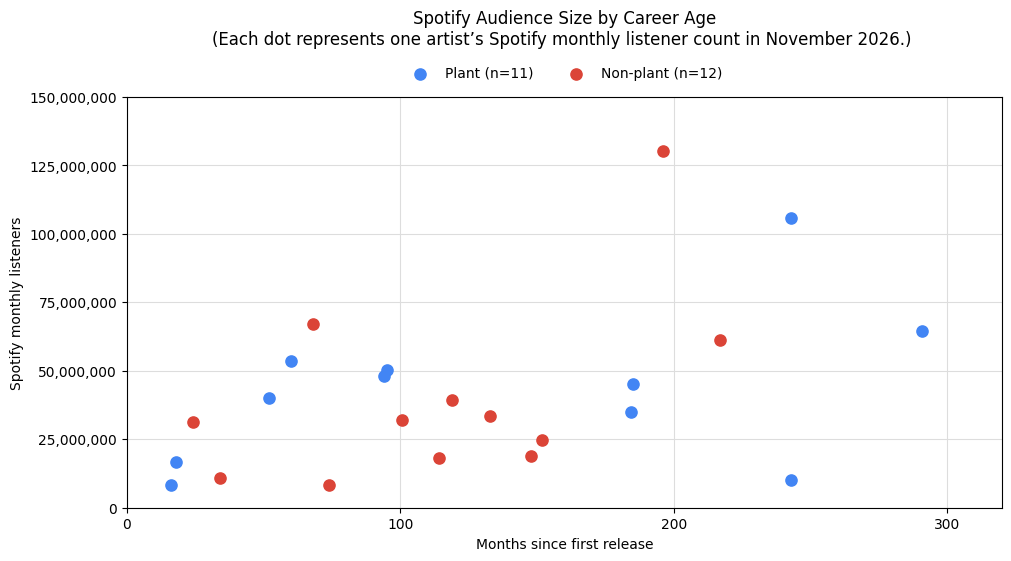

In [7]:
# Space to create visualizations (pls make sepreate boxes for each visual ty)
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

plot_data = df.dropna(subset=["monthly_listeners"])

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")

for flag, label, color in [
    ("Yes", "Plant", "#4285F4"),
    ("No", "Non-plant", "#DB4437"),
]:
    group = plot_data[plot_data["plant"] == flag]

    ax.scatter(
        group["months_since_release"],
        group["monthly_listeners"],
        s=65,
        color=color,
        label=f"{label} (n={len(group)})",
    )

ax.set_title("Spotify Audience Size by Career Age\n(Each dot represents one artist’s Spotify monthly listener count in November 2026.) ", pad=38)
ax.set_xlabel("Months since first release")
ax.set_ylabel("Spotify monthly listeners")

ax.set_xlim(0, 320)
ax.set_ylim(0, 150_000_000)
ax.set_xticks([0, 100, 200, 300])
ax.set_yticks(range(0, 150_000_001, 25_000_000))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

ax.set_axisbelow(True)
ax.grid(color="#dddddd")
ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=2,
    frameon=False,
)

plt.show()